In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path = "C:\\Users\\joshua\\OneDrive\\Desktop\\Data Analysis Projects\\Customer Segmentation\\Customer Segmentation.xlsx"
orig_df = pd.read_excel(file_path)
df = orig_df.copy()
print("Copied!")

Copied!


In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [6]:
df = df.dropna()
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64

In [7]:
df['Age'] = 2025 - df['Year_Birth']

In [8]:
df['Total Spent'] = df[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total Spent
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,0,0,0,3,11,1,68,1617
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,0,0,0,3,11,0,71,27
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,0,0,0,3,11,0,60,776
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,0,0,0,3,11,0,41,53
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,0,0,0,3,11,0,44,422


In [10]:
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], dayfirst = True)

In [11]:
df.dtypes

ID                              int64
Year_Birth                      int64
Education                      object
Marital_Status                 object
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[ns]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1                    int64
AcceptedCmp2                    int64
Complain                        int64
Z_CostContac

In [12]:
df['Total Campaign Accepted'] = df[['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2']].sum(axis = 1)

In [13]:
df['Children'] = df['Kidhome'] + df['Teenhome']
df.head(10)

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total Spent,Total Campaign Accepted,Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,3,11,1,68,1617,0,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,3,11,0,71,27,0,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,3,11,0,60,776,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,3,11,0,41,53,0,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,3,11,0,44,422,0,1
5,7446,1967,Master,Together,62513.0,0,1,2013-09-09,16,520,...,0,0,0,3,11,0,58,716,0,1
6,965,1971,Graduation,Divorced,55635.0,0,1,2012-11-13,34,235,...,0,0,0,3,11,0,54,590,0,1
7,6177,1985,PhD,Married,33454.0,1,0,2013-05-08,32,76,...,0,0,0,3,11,0,40,169,0,1
8,4855,1974,PhD,Together,30351.0,1,0,2013-06-06,19,14,...,0,0,0,3,11,1,51,46,0,1
9,5899,1950,PhD,Together,5648.0,1,1,2014-03-13,68,28,...,0,0,0,3,11,0,75,49,1,2


In [14]:
xlsx = "C:\\Users\\joshua\\OneDrive\\Desktop\\Data Analysis Projects\\Customer Segmentation\\Customer Segmentation(Clean).xlsx"
df.to_excel(xlsx, index=False)

In [15]:
#use to view summary statistics of the cleaned dataset
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total Spent,Total Campaign Accepted,Children
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,2013-07-10 11:29:27.509025280,49.012635,305.091606,26.356047,166.995939,...,0.064079,0.013538,0.009477,3.0,11.0,0.150271,56.179603,607.075361,0.298285,0.947202
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,29.000000,5.000000,0.000000,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,24.000000,2.000000,16.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,48.000000,69.000000,0.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,174.500000,8.000000,68.000000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,55.000000,396.500000,0.000000,1.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-31 00:00:00,74.000000,505.000000,33.000000,232.250000,...,0.000000,0.000000,0.000000,3.0,11.0,0.000000,66.000000,1048.000000,0.000000,1.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,1.000000,1.000000,1.000000,3.0,11.0,1.000000,132.000000,2525.000000,4.000000,3.000000
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,NaN,28.948352,337.327920,39.793917,224.283273,...,0.244950,0.115588,0.096907,0.0,0.0,0.357417,11.985554,602.900476,0.679209,0.749062


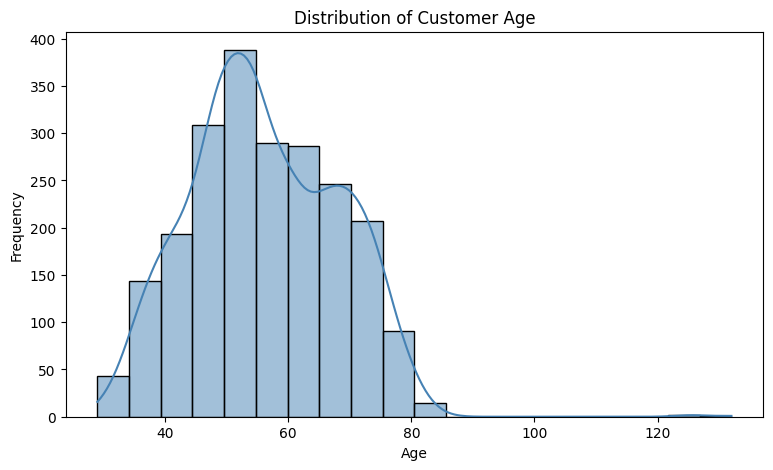

In [16]:
#visualize the distribution of customer age
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Age', bins=20, kde=True, color='steelblue')
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

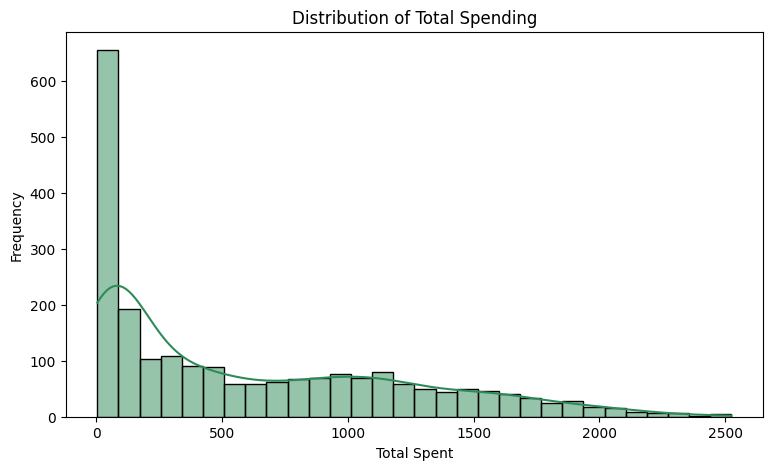

In [17]:
#visualize the distribution of total spending
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Total Spent', bins=30, kde=True, color='seagreen')
plt.title('Distribution of Total Spending')
plt.xlabel('Total Spent')
plt.ylabel('Frequency')
plt.show()

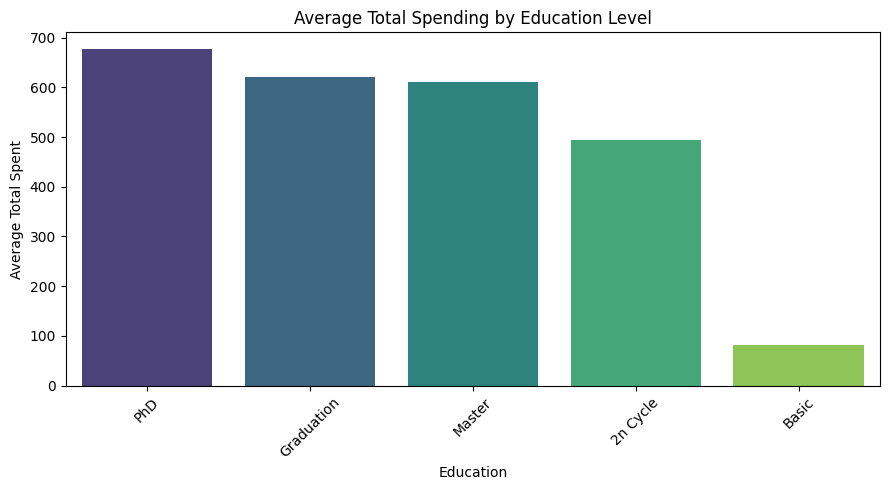

In [18]:
#visualize average spending by education level
avg_spend_edu = df.groupby('Education')['Total Spent'].mean().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=avg_spend_edu.index, y=avg_spend_edu.values, hue=avg_spend_edu.index, palette='viridis', legend=False)
plt.title('Average Total Spending by Education Level')
plt.xlabel('Education')
plt.ylabel('Average Total Spent')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

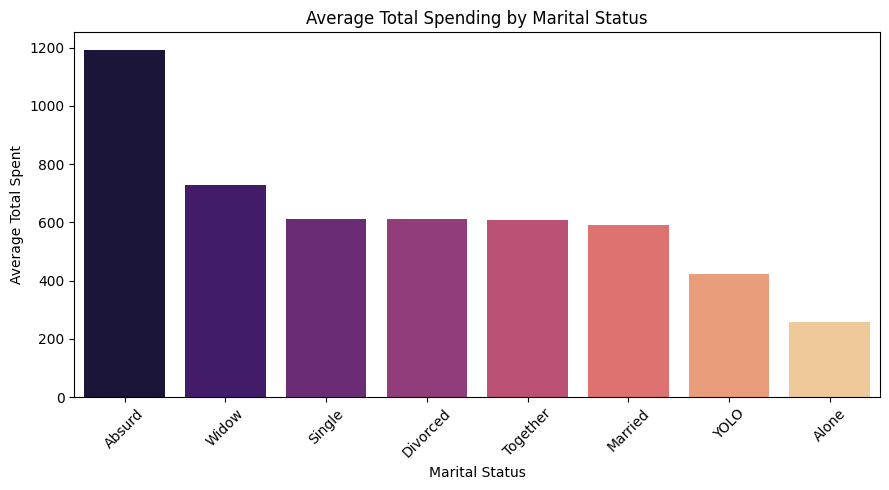

In [19]:
#visualize average spending by marital status
avg_spend_marital = df.groupby('Marital_Status')['Total Spent'].mean().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=avg_spend_marital.index, y=avg_spend_marital.values, hue=avg_spend_marital.index, palette='magma', legend=False)
plt.title('Average Total Spending by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Average Total Spent')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

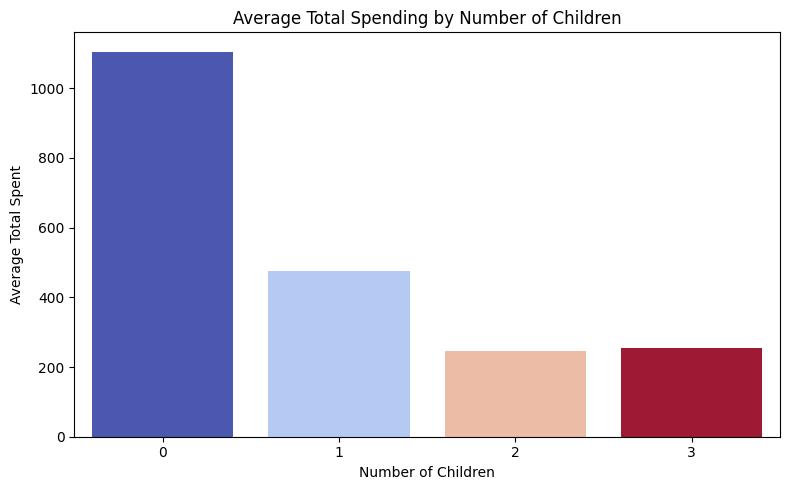

In [20]:
#visualize average spending by number of children
avg_spend_children = df.groupby('Children')['Total Spent'].mean()
plt.figure(figsize=(8, 5))
sns.barplot(x=avg_spend_children.index, y=avg_spend_children.values, hue=avg_spend_children.index, palette='coolwarm', legend=False)
plt.title('Average Total Spending by Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Average Total Spent')
plt.tight_layout()
plt.show()

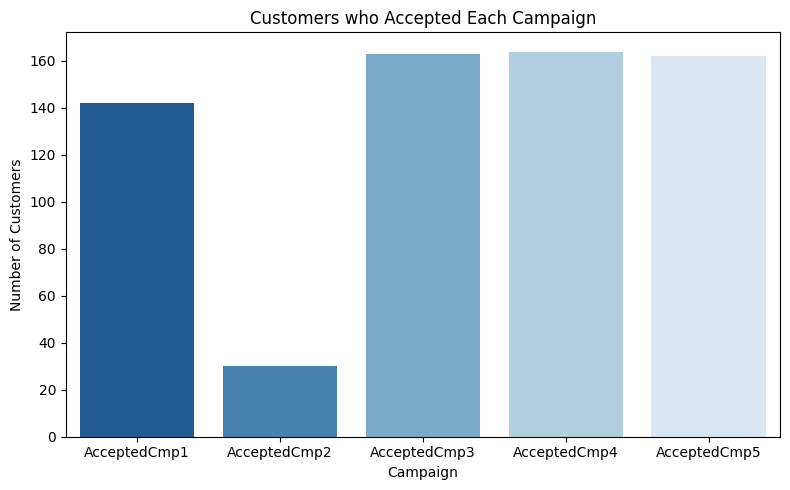

In [21]:
#visualize the number of customers who accepted each campaign
campaigns = df[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']].sum()
plt.figure(figsize=(8, 5))
sns.barplot(x=campaigns.index, y=campaigns.values, hue=campaigns.index, palette='Blues_r', legend=False)
plt.title('Customers who Accepted Each Campaign')
plt.xlabel('Campaign')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

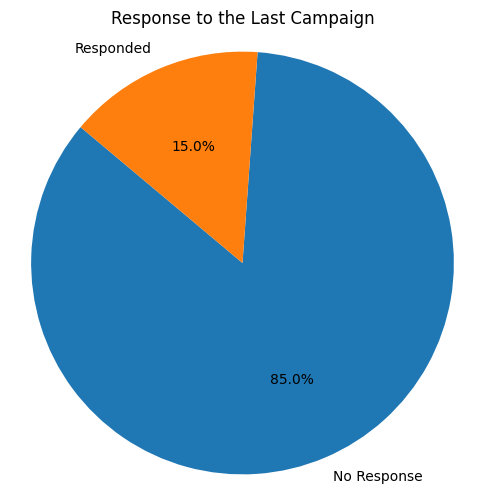

In [22]:
#visualize the share of customers who responded to the last campaign
responded = df['Response'].value_counts()
response_labels = responded.index.map({0: 'No Response', 1: 'Responded'})
plt.figure(figsize=(6, 6))
plt.pie(responded, labels=response_labels, autopct='%1.1f%%', startangle=140)
plt.title('Response to the Last Campaign')
plt.axis('equal')
plt.show()

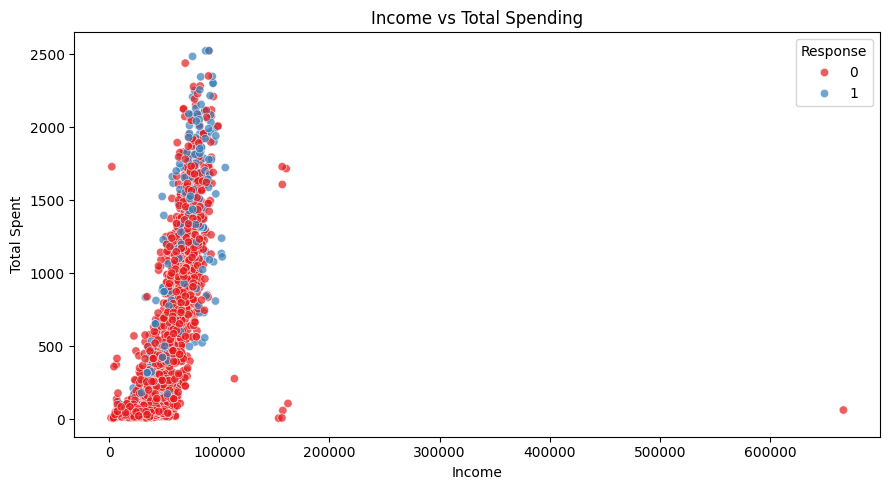

In [23]:
#visualize the relationship between income and total spending
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Income', y='Total Spent', hue='Response', palette='Set1', alpha=0.7)
plt.title('Income vs Total Spending')
plt.xlabel('Income')
plt.ylabel('Total Spent')
plt.tight_layout()
plt.show()

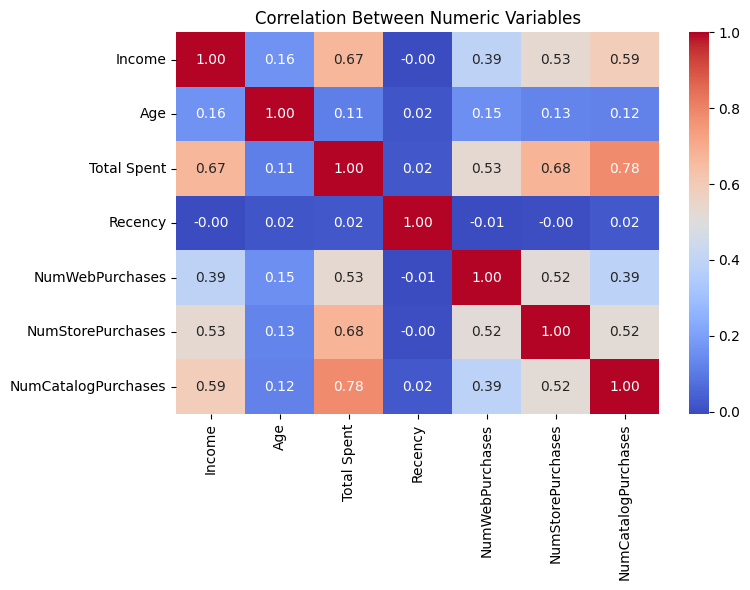

In [24]:
#visualize the correlation between selected numeric variables
num_cols = ['Income', 'Age', 'Total Spent', 'Recency', 'NumWebPurchases', 'NumStorePurchases', 'NumCatalogPurchases']
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Between Numeric Variables')
plt.tight_layout()
plt.show()

Spending Segment
Low          554
Medium       554
High         554
Very High    554
Name: count, dtype: int64


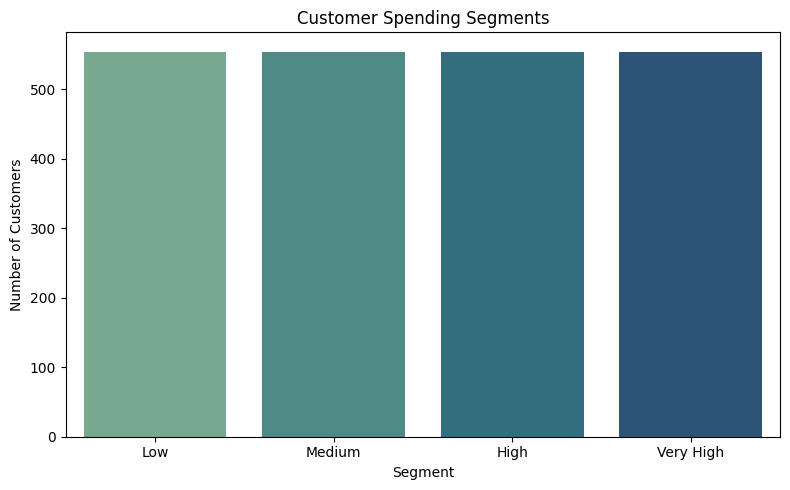

In [25]:
#segment customers into spending groups based on spending quartiles
df['Spending Segment'] = pd.qcut(df['Total Spent'].rank(method='first'), q=4, labels=['Low', 'Medium', 'High', 'Very High'])
segment_counts = df['Spending Segment'].value_counts().reindex(['Low', 'Medium', 'High', 'Very High'])
print(segment_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=segment_counts.index, y=segment_counts.values, hue=segment_counts.index, palette='crest', legend=False)
plt.title('Customer Spending Segments')
plt.xlabel('Segment')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()